# Replikasi Peramalan Beban Listrik dengan Apache Spark (Low Carbon London)

**Tugas Eksplorasi Mandiri Mahadata (IF25-40402)**

Artikel acuan: Ali, H. A. E.-S., Alham, M. H., & Ibrahim, D. K. (2024). Big data resolving using Apache Spark for load forecasting and demand response in smart grid: A case study of Low Carbon London Project. *Journal of Big Data, 11*, Article 59. https://doi.org/10.1186/s40537-024-00909-6


## Fase 0 Setup

In [ ]:
#install beberapa library
!pip -q install pyspark pandas matplotlib seaborn

In [ ]:
import os, sys, glob, time, platform, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import pyspark
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import StructType, StructField, StringType

SEED = 42
BLOCKS = [0]            # Fase 0-4: cukup Block 0 (±50 rumah). Fase 5(a) bisa diperluas, mis. [0, 1, 2, 3, 4]

# Lokasi folder (notebook ada di notebooks/, akar repo satu tingkat di atas)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = Path(os.environ.get("LCL_DATA_DIR", ROOT / "data"))
RESULTS_DIR, FIG_DIR = ROOT / "results", ROOT / "figures"
for d in (RESULTS_DIR, FIG_DIR, DATA_DIR / "processed"):
    d.mkdir(parents=True, exist_ok=True)

# SparkSession mode lokal
spark = (SparkSession.builder.master("local[*]").appName("lcl-replikasi")
         .config("spark.driver.memory", "6g")
         .config("spark.sql.shuffle.partitions", "16")
         .config("spark.sql.session.timeZone", "UTC")         # hindari pergeseran jam akibat zona waktu/DST
         .config("spark.sql.ansi.enabled", "false")           # cast "Null" -> null, bukan error (default ANSI di Spark 4 = true)
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

try:
    java_ver = subprocess.run(["java", "-version"], capture_output=True, text=True).stderr.splitlines()[0]
except Exception:
    java_ver = "tidak terdeteksi"
versions = pd.DataFrame({
    "komponen": ["OS", "Python", "Java", "Spark", "pyspark", "pandas", "master", "driver memory", "seed"],
    "versi": [platform.platform(), sys.version.split()[0], java_ver, spark.version, pyspark.__version__,
              pd.__version__, spark.sparkContext.master, spark.conf.get("spark.driver.memory"), SEED]})
versions.to_csv(RESULTS_DIR / "versi_lingkungan.csv", index=False)
print("Spark", spark.version)
versions

Spark 4.0.4


,komponen,versi
0,OS,Linux-6.6.122+-x86_64-with-glibc2.39
1,Python,3.13.15
2,Java,"openjdk version ""21.0.12.1"" 2026-08-18"
3,Spark,4.0.4
4,pyspark,4.0.4
5,pandas,2.2.3
6,master,local[*]
7,driver memory,6g
8,seed,42


In [ ]:
# Memuat dataset yang langsung dihubungkan ke kaggle dengan membuat penghubung (link)
# antara google colab dan Kaggle.
# Langkah-langkahnya adalah:
# 1. login ke Kaggle dan masuk ke menu Your API Token (dengan klik tombol profile akun di
# pojok kanan atas). Selanjutnya ambil Token melalui "Create Legacy API Key"
# 2. Setelah diunduh file kaggle.json maka diunggah ke google drive
# (misal pada path: My Drive/kaggle.json)
# 3. Melakukan instalasi Library Kaggle
! pip install kaggle
# 4. Membuat direktori dengan nama '.kaggle'
! mkdir ~/.kaggle
# 5. Melakukan copy file 'kaggle.json' ke dalam direktori yang baru tersebut
! cp '/content/drive/MyDrive/kaggle.json' ~/.kaggle/
# 6. Memberikan izin akses untuk file tersebut
! chmod 600 ~/.kaggle/kaggle.json

# 7. Download Animal Image Dataset dari Kaggle
! kaggle datasets download "jeanmidev/smart-meters-in-london"

mkdir: cannot create directory ‘/root/.kaggle’: File exists
cp: cannot stat '/content/drive/MyDrive/kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/jeanmidev/smart-meters-in-london
License(s): ODbL-1.0
100% 1.17G/1.17G [01:09<00:00, 18.0MB/s]



In [ ]:
# Ekstrak file zip di dalam folder data
!unzip -q -o "sample_data/smart-meters-in-london.zip" -d data/

unzip:  cannot find or open sample_data/smart-meters-in-london.zip, sample_data/smart-meters-in-london.zip.zip or sample_data/smart-meters-in-london.zip.ZIP.


## Fase 1 Data dan pembersihan

### Sel 1 Baca data
Sumber: Kaggle *Smart meters in London* (turunan Low Carbon London). Letakkan berkas di `data/` (lihat `data/README_data.md`):

- `halfhourly_dataset/**/block_*.csv` → kolom `LCLid`, `tstp`, `energy(kWh/hh)`
- `weather_hourly_darksky.csv`
- `uk_bank_holidays.csv`

Skema dibaca sebagai teks lebih dulu, karena kolom energi memuat string `"Null"` sehingga `inferSchema` akan salah menebak.

In [ ]:
def find_one(pattern):
    hits = sorted(glob.glob(str(DATA_DIR / "**" / pattern), recursive=True))
    if not hits:
        raise FileNotFoundError(f"'{pattern}' tidak ditemukan di {DATA_DIR}. Lihat data/README_data.md untuk cara mengunduh.")
    return hits[0]

block_files = [find_one(f"block_{b}.csv") for b in BLOCKS]
print("Berkas blok:", *block_files, sep="\n  ")

raw_schema = StructType([StructField("LCLid", StringType()),
                         StructField("tstp", StringType()),
                         StructField("energy", StringType())])

# header=True lalu skema eksplisit: kolom dibaca berurutan, nama asli "energy(kWh/hh)" diganti "energy"
raw = (spark.read.csv(block_files, header=True, schema=raw_schema, enforceSchema=True))

print("Skema data mentah:")
raw.printSchema()
n_raw = raw.count()
raw.show(5, truncate=False)

info_raw = raw.agg(F.countDistinct("LCLid").alias("n_rumah"),
                   F.min("tstp").alias("tstp_min"), F.max("tstp").alias("tstp_max")).toPandas()
info_raw.insert(0, "n_baris_mentah", n_raw)
info_raw.insert(0, "blok", ",".join(map(str, BLOCKS)))
info_raw.to_csv(RESULTS_DIR / "fase1_sel1_data_mentah.csv", index=False)
info_raw

Berkas blok:
  /content/data/daily_dataset/daily_dataset/block_0.csv
Skema data mentah:
root
 |-- LCLid: string (nullable = true)
 |-- tstp: string (nullable = true)
 |-- energy: string (nullable = true)

+---------+----------+-------------------+
|LCLid    |tstp      |energy             |
+---------+----------+-------------------+
|MAC000002|2012-10-12|0.1385             |
|MAC000002|2012-10-13|0.18               |
|MAC000002|2012-10-14|0.158              |
|MAC000002|2012-10-15|0.131              |
|MAC000002|2012-10-16|0.14500000000000002|
+---------+----------+-------------------+
only showing top 5 rows


,blok,n_baris_mentah,n_rumah,tstp_min,tstp_max
0,0,25574,50,2011-12-03,2014-02-28


### Sel 2 Pembersihan
Mengikuti artikel: nilai null dan nol dianggap pemadaman/gangguan komunikasi, jadi dibuang.

In [ ]:
# Parse timestamp: ambil 19 karakter pertama ("yyyy-MM-dd HH:mm:ss"), pecahan detik 7 digit diabaikan
typed = (raw.withColumn("energy", F.col("energy").cast("double"))        # "Null" -> null
            .withColumn("ts", F.to_timestamp(F.substring("tstp", 1, 19))))

counts = typed.agg(
    F.count(F.lit(1)).alias("total"),
    F.sum(F.col("energy").isNull().cast("int")).alias("energy_null"),
    F.sum(F.col("ts").isNull().cast("int")).alias("ts_null"),
    F.sum((F.col("energy") == 0).cast("int")).alias("energy_nol"),
    F.sum((F.col("energy") < 0).cast("int")).alias("energy_negatif")).first()

clean = (typed.dropna(subset=["energy", "ts"])
              .filter(F.col("energy") > 0)
              .select("LCLid", "ts", "energy"))
n_clean = clean.count()

cleaning_summary = pd.DataFrame([
    ("Baris mentah", counts["total"]),
    ("  energy null (\"Null\"/kosong)", counts["energy_null"]),
    ("  timestamp gagal di-parse", counts["ts_null"]),
    ("  energy = 0", counts["energy_nol"]),
    ("  energy < 0", counts["energy_negatif"]),
    ("Baris setelah pembersihan", n_clean),
    ("Baris dibuang", counts["total"] - n_clean),
    ("Persentase dibuang (%)", round(100 * (counts["total"] - n_clean) / counts["total"], 3)),
], columns=["keterangan", "nilai"]).astype({"nilai": object})
cleaning_summary["nilai"] = cleaning_summary["nilai"].map(lambda v: str(int(v)) if float(v).is_integer() else str(v))  # angka bulat tampil tanpa ".0"
cleaning_summary.to_csv(RESULTS_DIR / "fase1_sel2_pembersihan.csv", index=False)
cleaning_summary

,keterangan,nilai
0,Baris mentah,25574
1,"energy null (""Null""/kosong)",0
2,timestamp gagal di-parse,0
3,energy = 0,0
4,energy < 0,0
5,Baris setelah pembersihan,25574
6,Baris dibuang,0
7,Persentase dibuang (%),0


### Sel 3 Agregasi per timestamp, join cuaca (per jam) dan hari libur
Target `energy_sum` = jumlah energi seluruh rumah di blok pada tiap timestamp; `n_house` = jumlah rumah yang tercatat pada timestamp itu.

In [ ]:
# Agregasi per timestamp
agg = (clean.groupBy("ts")
            .agg(F.sum("energy").alias("energy_sum"),
                 F.countDistinct("LCLid").alias("n_house")))

# Cuaca per jam (Dark Sky)
wx_raw = spark.read.csv(find_one("weather_hourly_darksky.csv"), header=True, inferSchema=True)
missing = {"time", "apparentTemperature"} - set(wx_raw.columns)
assert not missing, f"Kolom cuaca tidak ada: {missing}. Kolom tersedia: {wx_raw.columns}"
wx = (wx_raw.select(F.date_trunc("hour", F.to_timestamp("time")).alias("hr"),
                    F.col("apparentTemperature").cast("double").alias("app_temp"))
            .groupBy("hr").agg(F.avg("app_temp").alias("app_temp")))     # 1 baris per jam -> join tidak menggandakan baris
print("Cuaca: baris mentah", wx_raw.count(), "| jam unik", wx.count())

# Hari libur (UK bank holidays)
hol_raw = spark.read.csv(find_one("uk_bank_holidays.csv"), header=True)
hol_col = hol_raw.columns[0]                                              # kolom tanggal ("Bank holidays")
hol = (hol_raw.select(F.to_date(F.col(f"`{hol_col}`")).alias("d")).dropna().distinct()
              .withColumn("is_hol", F.lit(1)))
print("Hari libur:", hol.count(), "tanggal | kolom tanggal =", repr(hol_col))

# Gabungkan + fitur waktu
df = (agg.withColumn("hr", F.date_trunc("hour", "ts"))
         .join(wx, "hr", "left")
         .withColumn("d", F.to_date("ts"))
         .join(hol, "d", "left")
         .withColumn("hour", F.hour("ts"))
         .withColumn("weekend", F.when(F.dayofweek("ts").isin(1, 7) | (F.col("is_hol") == 1), 1).otherwise(0))
         .select("ts", "energy_sum", "n_house", "app_temp", "hour", "weekend"))

n_agg = df.count()
df = df.dropna(subset=["app_temp"]).cache()      # timestamp tanpa data cuaca dibuang
n_final = df.count()
print(f"Timestamp setelah agregasi: {n_agg:,} | setelah join cuaca (tanpa null): {n_final:,} | dibuang: {n_agg - n_final:,}")
df.orderBy("ts").show(5, truncate=False)

Cuaca: baris mentah 21165 | jam unik 21165
Hari libur: 25 tanggal | kolom tanggal = 'Bank holidays'
Timestamp setelah agregasi: 819 | setelah join cuaca (tanpa null): 818 | dibuang: 1
+-------------------+-------------------+-------+--------+----+-------+
|ts                 |energy_sum         |n_house|app_temp|hour|weekend|
+-------------------+-------------------+-------+--------+----+-------+
|2011-12-03 00:00:00|0.11499999999999999|1      |4.71    |0   |1      |
|2011-12-04 00:00:00|0.175              |1      |6.13    |0   |1      |
|2011-12-05 00:00:00|0.078              |1      |0.17    |0   |0      |
|2011-12-06 00:00:00|0.114              |1      |-0.89   |0   |0      |
|2011-12-07 00:00:00|0.10350000000000001|1      |3.17    |0   |0      |
+-------------------+-------------------+-------+--------+----+-------+
only showing top 5 rows


### Validasi akhir Fase 1 dan simpan artefak
**Selesai jika:** DataFrame final berisi `energy_sum`, `n_house`, `app_temp`, `hour`, `weekend` tanpa null.

In [ ]:
needed = ["energy_sum", "n_house", "app_temp", "hour", "weekend"]
assert all(c in df.columns for c in needed), "Kolom final belum lengkap"
null_per_col = df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in needed]).first().asDict()
assert all(v == 0 for v in null_per_col.values()), f"Masih ada null: {null_per_col}"
print(" Fase 1 lolos: tidak ada null pada", needed, "| baris:", f"{n_final:,}")

# 5 baris contoh (cf. Tabel 4 artikel) untuk laporan
sample5 = df.orderBy("ts").limit(5).toPandas()
sample5.to_csv(RESULTS_DIR / "fase1_contoh_5_baris.csv", index=False)

# ringkasan alur data Fase 1
pd.DataFrame([("baris mentah", n_raw), ("setelah pembersihan", n_clean),
              ("timestamp teragregasi", n_agg), ("timestamp final (ada cuaca)", n_final)],
             columns=["tahap", "jumlah"]).to_csv(RESULTS_DIR / "fase1_ringkasan_alur.csv", index=False)

# simpan parquet agar Fase 2+ tidak mengulang dari CSV (folder data/ tidak di-commit)
df.write.mode("overwrite").parquet(str(DATA_DIR / "processed" / "df_final.parquet"))

# statistik ringkas fitur
df.select(needed).describe().toPandas()

 Fase 1 lolos: tidak ada null pada ['energy_sum', 'n_house', 'app_temp', 'hour', 'weekend'] | baris: 818


,summary,energy_sum,n_house,app_temp,hour,weekend
0,count,818,818,818,818,818
1,mean,11.43932151693154,31.206601466992666,7.894853300733495,0.0,0.30684596577017115
2,stddev,7.307615960567611,19.947915176588875,6.223403988172004,0.0,0.46146706426072676
3,min,0.0635,1,-8.52,0,0
4,max,28.886499900000004,50,22.59,0,1


In [ ]:
sample5

,ts,energy_sum,n_house,app_temp,hour,weekend
0,2011-12-03,0.1150,1,4.71,0,1
1,2011-12-04,0.1750,1,6.13,0,1
2,2011-12-05,0.0780,1,0.17,0,0
3,2011-12-06,0.1140,1,-0.89,0,0
4,2011-12-07,0.1035,1,3.17,0,0


## Fase 2 Deskriptif dan seleksi fitur

Semua kueri deskriptif memakai **Spark SQL** pada *temp view* `lcl` (dari `df`). Hasil kecil (≤ puluhan baris) diubah ke pandas hanya untuk digambar. Tabel tersimpan di `results/fase2_*.csv`, grafik di `figures/fase2_*.png`.

ACORN tidak dipakai: model per blok memakai `n_house`, bukan kategori ACORN (kategori itu hanya untuk model "semua rumah" di artikel).

### Sel 4 Analitik deskriptif (Spark SQL)

In [ ]:
import matplotlib.pyplot as plt

df.createOrReplaceTempView("lcl")

def save_fig(name):
    """Simpan figur aktif ke figures/<name>.png lalu tampilkan."""
    path = FIG_DIR / f"{name}.png"
    plt.tight_layout(); plt.savefig(path, dpi=150, bbox_inches="tight"); plt.show()
    return path

# Konteks: jumlah rumah per timestamp bisa berubah sepanjang waktu -> memengaruhi skala energy_sum
n_house_stats = spark.sql(
    "SELECT MIN(n_house) AS n_house_min, ROUND(AVG(n_house), 1) AS n_house_rata2, MAX(n_house) AS n_house_max, "
    "MIN(ts) AS ts_min, MAX(ts) AS ts_max, COUNT(*) AS n_timestamp FROM lcl").toPandas()
n_house_stats.to_csv(RESULTS_DIR / "fase2_n_house_stats.csv", index=False)
n_house_stats

,n_house_min,n_house_rata2,n_house_max,ts_min,ts_max,n_timestamp
0,1,31.2,50,2011-12-03,2014-02-28,818


**4a. Rata-rata beban per jam** (pola harian)

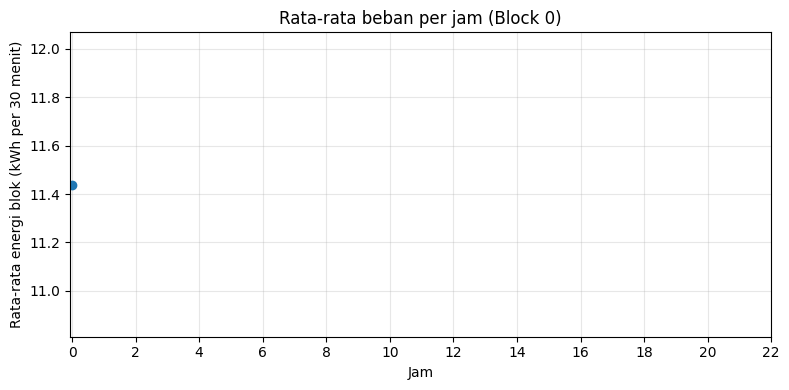

PosixPath('/content/figures/fase2_beban_per_jam.png')

In [ ]:
hourly = spark.sql("""
    SELECT hour, AVG(energy_sum) AS avg_kwh
    FROM lcl GROUP BY hour ORDER BY hour""").toPandas()
hourly.to_csv(RESULTS_DIR / "fase2_beban_per_jam.csv", index=False)

plt.figure(figsize=(8, 4))
plt.plot(hourly["hour"], hourly["avg_kwh"], marker="o")
plt.xticks(range(0, 24, 2)); plt.xlabel("Jam"); plt.ylabel("Rata-rata energi blok (kWh per 30 menit)")
plt.title("Rata-rata beban per jam (Block 0)"); plt.grid(alpha=.3)
save_fig("fase2_beban_per_jam")

**4b. Rata-rata per bulan vs suhu** (pola musiman; bulan dikelompokkan lintas tahun)

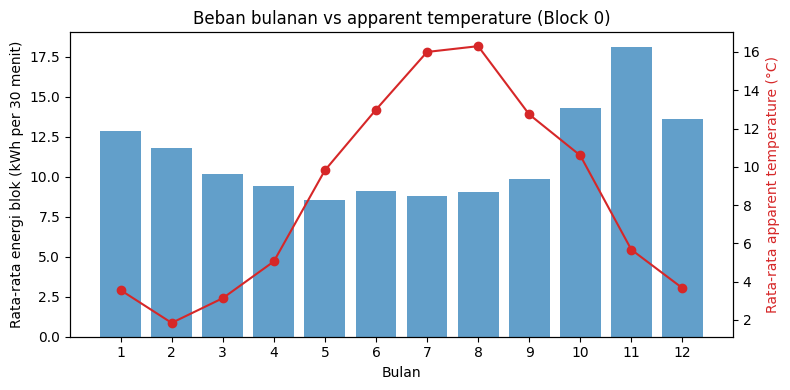

PosixPath('/content/figures/fase2_bulanan_vs_suhu.png')

In [ ]:
monthly = spark.sql("""
    SELECT month(ts) AS month, AVG(energy_sum) AS avg_kwh, AVG(app_temp) AS avg_app_temp
    FROM lcl GROUP BY month(ts) ORDER BY month""").toPandas()
monthly.to_csv(RESULTS_DIR / "fase2_bulanan_vs_suhu.csv", index=False)

fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.bar(monthly["month"], monthly["avg_kwh"], color="tab:blue", alpha=.7)
ax1.set_xlabel("Bulan"); ax1.set_ylabel("Rata-rata energi blok (kWh per 30 menit)"); ax1.set_xticks(range(1, 13))
ax2 = ax1.twinx()
ax2.plot(monthly["month"], monthly["avg_app_temp"], color="tab:red", marker="o")
ax2.set_ylabel("Rata-rata apparent temperature (°C)", color="tab:red")
plt.title("Beban bulanan vs apparent temperature (Block 0)")
save_fig("fase2_bulanan_vs_suhu")

**4c. Akhir pekan/libur vs hari kerja** (profil per jam)

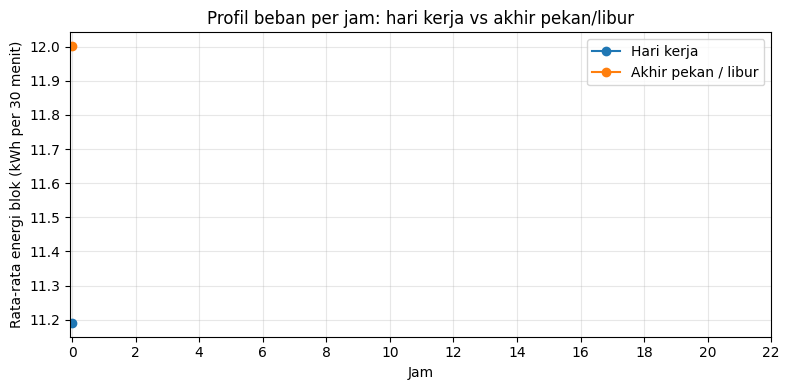

PosixPath('/content/figures/fase2_weekend_vs_weekday.png')

In [ ]:
weekend_hourly = spark.sql("""
    SELECT weekend, hour, AVG(energy_sum) AS avg_kwh
    FROM lcl GROUP BY weekend, hour ORDER BY weekend, hour""").toPandas()
weekend_hourly.to_csv(RESULTS_DIR / "fase2_weekend_vs_weekday.csv", index=False)

plt.figure(figsize=(8, 4))
for w, label in [(0, "Hari kerja"), (1, "Akhir pekan / libur")]:
    s = weekend_hourly[weekend_hourly["weekend"] == w]
    plt.plot(s["hour"], s["avg_kwh"], marker="o", label=label)
plt.xticks(range(0, 24, 2)); plt.xlabel("Jam"); plt.ylabel("Rata-rata energi blok (kWh per 30 menit)")
plt.title("Profil beban per jam: hari kerja vs akhir pekan/libur"); plt.legend(); plt.grid(alpha=.3)
save_fig("fase2_weekend_vs_weekday")

**4d. Beban vs suhu** (rata-rata energi per bin suhu 1 °C; dasar memilih model polinomial)

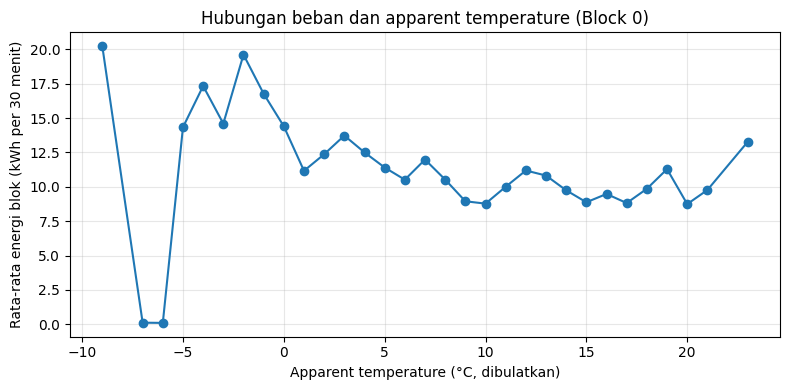

,temp_bin,avg_kwh,n_timestamp
0,-9.0,20.228000,1
1,-7.0,0.120000,1
2,-6.0,0.105750,2
3,-5.0,14.335125,4
4,-4.0,17.330100,5


In [ ]:
temp_curve = spark.sql("""
    SELECT ROUND(app_temp) AS temp_bin, AVG(energy_sum) AS avg_kwh, COUNT(*) AS n_timestamp
    FROM lcl GROUP BY ROUND(app_temp) ORDER BY temp_bin""").toPandas()
temp_curve.to_csv(RESULTS_DIR / "fase2_beban_vs_suhu.csv", index=False)

plt.figure(figsize=(8, 4))
plt.plot(temp_curve["temp_bin"], temp_curve["avg_kwh"], marker="o")
plt.xlabel("Apparent temperature (°C, dibulatkan)"); plt.ylabel("Rata-rata energi blok (kWh per 30 menit)")
plt.title("Hubungan beban dan apparent temperature (Block 0)"); plt.grid(alpha=.3)
save_fig("fase2_beban_vs_suhu")
temp_curve.head()

### Sel 5 Seleksi fitur (korelasi Pearson)
Cuaca dibaca ulang lengkap (suhu udara, *dew point*, kelembapan, dll.) hanya untuk analisis korelasi; DataFrame `df` tidak diubah.

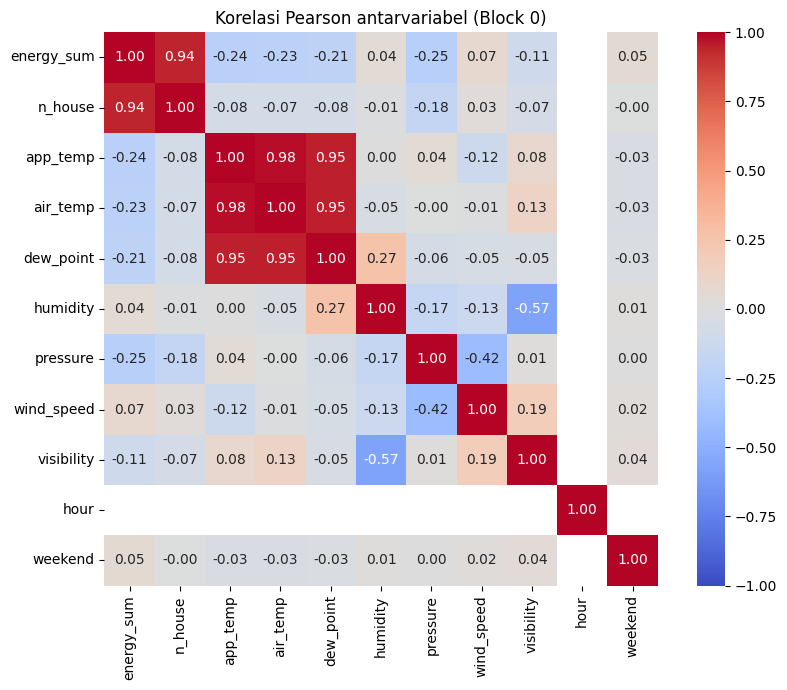

PosixPath('/content/figures/fase2_heatmap_korelasi.png')

In [ ]:
import seaborn as sns
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation

COLLINEAR_THRESHOLD = 0.8   # |r| >= 0.8 dianggap kolinear

# Kolom cuaca kandidat (hanya yang ada di berkas) -> nama ringkas
wx_cols = {"temperature": "air_temp", "dewPoint": "dew_point", "humidity": "humidity",
           "pressure": "pressure", "windSpeed": "wind_speed", "visibility": "visibility"}
wx_cols = {k: v for k, v in wx_cols.items() if k in wx_raw.columns}

wx_all = (wx_raw.select(F.date_trunc("hour", F.to_timestamp("time")).alias("hr"),
                        *[F.col(k).cast("double").alias(v) for k, v in wx_cols.items()])
                .groupBy("hr").agg(*[F.avg(v).alias(v) for v in wx_cols.values()]))

df_corr = (df.withColumn("hr", F.date_trunc("hour", "ts")).join(wx_all, "hr", "left").drop("hr", "ts"))

corr_cols = ["energy_sum", "n_house", "app_temp", *wx_cols.values(), "hour", "weekend"]
vec = VectorAssembler(inputCols=corr_cols, outputCol="vec", handleInvalid="skip").transform(df_corr).select("vec")
corr_matrix = pd.DataFrame(Correlation.corr(vec, "vec", "pearson").head()[0].toArray(),
                           index=corr_cols, columns=corr_cols)
corr_matrix.round(4).to_csv(RESULTS_DIR / "fase2_korelasi.csv", index_label="variabel")

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Korelasi Pearson antarvariabel (Block 0)")
save_fig("fase2_heatmap_korelasi")

In [ ]:
# Pasangan fitur cuaca yang kolinear
weather_feats = ["app_temp", *wx_cols.values()]
collinear_pairs = pd.DataFrame(
    [(a, b, corr_matrix.loc[a, b]) for i, a in enumerate(weather_feats) for b in weather_feats[i + 1:]
     if abs(corr_matrix.loc[a, b]) >= COLLINEAR_THRESHOLD],
    columns=["fitur_a", "fitur_b", "r"]).sort_values("r", key=abs, ascending=False)
collinear_pairs.to_csv(RESULTS_DIR / "fase2_pasangan_kolinear.csv", index=False)

# Korelasi tiap kandidat dengan target
target_corr = (corr_matrix["energy_sum"].drop("energy_sum").rename("r_dengan_energy_sum").to_frame()
               .assign(abs_r=lambda x: x["r_dengan_energy_sum"].abs()).sort_values("abs_r", ascending=False))
target_corr.to_csv(RESULTS_DIR / "fase2_korelasi_dengan_target.csv", index_label="fitur")

# Fitur akhir (mengikuti artikel: model per blok = 4 fitur; hanya app_temp dari kelompok suhu)
feat = ["n_house", "app_temp", "hour", "weekend"]
assert all(c in df.columns for c in feat)
dropped_feats = [c for c in weather_feats if c not in feat]
max_r_feat = corr_matrix.loc[feat, feat].where(~np.eye(len(feat), dtype=bool)).abs().max().max()
print("Fitur terpilih :", feat)
print("Fitur dibuang  :", dropped_feats)
print(f"|r| tertinggi antar fitur terpilih: {max_r_feat:.2f} (ambang kolinear {COLLINEAR_THRESHOLD})")
display(collinear_pairs); display(target_corr)

Fitur terpilih : ['n_house', 'app_temp', 'hour', 'weekend']
Fitur dibuang  : ['air_temp', 'dew_point', 'humidity', 'pressure', 'wind_speed', 'visibility']
|r| tertinggi antar fitur terpilih: 0.08 (ambang kolinear 0.8)


,fitur_a,fitur_b,r
0,app_temp,air_temp,0.983033
2,air_temp,dew_point,0.950838
1,app_temp,dew_point,0.948351


,r_dengan_energy_sum,abs_r
n_house,0.937702,0.937702
pressure,-0.251594,0.251594
app_temp,-0.241158,0.241158
air_temp,-0.232266,0.232266
dew_point,-0.212624,0.212624
visibility,-0.105296,0.105296
wind_speed,0.074522,0.074522
weekend,0.051283,0.051283
humidity,0.044199,0.044199
hour,NaN,NaN


## Fase 3 Modeling (MPR dan DTR)

Target `energy_sum`, fitur `feat` (`n_house`, `app_temp`, `hour`, `weekend`). Dua keluarga model:

| Model  | Isi |
|---|---|
| `Plain`, `Ridge`, `Lasso`, `ElasticNet` | MPR: ekspansi polinomial (`POLY_DEGREE`) + `LinearRegression`. Plain tanpa regularisasi; Ridge `elasticNetParam=0`; Lasso `=1`; ElasticNet `=0.5`. λ (`regParam`) dipilih dari `lam` dengan CV `CV_FOLDS`-fold, metrik tuning R² |
| `DTR(depth=5)` | `DecisionTreeRegressor(maxDepth=5)` pada fitur mentah, tanpa tuning |

Evaluasi pada `test` (20%): `r2`, `mae`, `mse`, `rmse`, `fit_s`, `test_s`. Tabel tersimpan di `results/metrics_block0.csv`.

### Sel 6 Split dan definisi model

In [ ]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import PolynomialExpansion
from pyspark.ml.regression import LinearRegression, DecisionTreeRegressor
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder

POLY_DEGREE = 2   # derajat polinomial MPR (asumsi; artikel tidak dicek -> verifikasi ke naskah)
CV_FOLDS = 3      # cross-validation 3-fold (mengikuti rencana metode)

# --- Split 80/20, seed tunggal; cache agar pembagian tetap sama di semua model ---
train, test = df.randomSplit([0.8, 0.2], seed=SEED)
train, test = train.cache(), test.cache()
n_train, n_test = train.count(), test.count()
assert n_train + n_test == n_final, "Split tidak menjumlah ke n_final"
print(f"Train: {n_train:,} ({n_train / n_final:.1%}) | Test: {n_test:,} ({n_test / n_final:.1%}) | feat = {feat}")

# --- Praproses pipeline (kolom vektor internal feat_vec/feat_poly tidak masuk df) ---
mpr_prep = [VectorAssembler(inputCols=feat, outputCol="feat_vec"),
            PolynomialExpansion(degree=POLY_DEGREE, inputCol="feat_vec", outputCol="feat_poly")]
dtr_prep = [VectorAssembler(inputCols=feat, outputCol="feat_vec")]

# --- Estimator ---
# standardization=True (default MLlib): fitur polinomial diskalakan internal, penting untuk Ridge/Lasso/EN
lr = LinearRegression(featuresCol="feat_poly", labelCol="energy_sum", standardization=True)
lam = [1e-5, 1e-4, 1e-3, 1e-2]          # grid regParam (λ) untuk Ridge, Lasso, ElasticNet
dtr = DecisionTreeRegressor(featuresCol="feat_vec", labelCol="energy_sum", maxDepth=5, seed=SEED)

Train: 662 (80.9%) | Test: 156 (19.1%) | feat = ['n_house', 'app_temp', 'hour', 'weekend']


### Sel 7 CV, fit, dan uji tiap model
`run` mengembalikan satu dict metrik per model. Model dengan grid λ memakai `CrossValidator` (4 nilai λ × 3 fold + 1 refit pada seluruh `train`).

In [ ]:
def run(name, prep, est, grid=None):
    """CV (bila ada grid λ) + fit + uji satu model. `grid` = daftar nilai regParam (mis. lam) atau None."""
    pipe = Pipeline(stages=[*prep, est])
    ev = RegressionEvaluator(labelCol="energy_sum", predictionCol="prediction", metricName="r2")  # metrik tuning = R²

    t0 = time.perf_counter()                       # fit_s = seluruh waktu .fit(), termasuk CV bila ada
    if grid:
        maps = ParamGridBuilder().addGrid(est.regParam, grid).build()
        model = CrossValidator(estimator=pipe, estimatorParamMaps=maps, evaluator=ev,
                               numFolds=CV_FOLDS, seed=SEED).fit(train)
        best_lam = model.bestModel.stages[-1].getRegParam()
    else:
        model, best_lam = pipe.fit(train), None
    fit_s = time.perf_counter() - t0

    t0 = time.perf_counter()                       # test_s = transform pada test; noop memaksa komputasi penuh
    pred = model.transform(test)
    pred.write.format("noop").mode("overwrite").save()
    test_s = time.perf_counter() - t0

    out = {"model": name, **{k: ev.evaluate(pred, {ev.metricName: k}) for k in ["r2", "mae", "mse", "rmse"]},
           "fit_s": fit_s, "test_s": test_s, "best_lam": best_lam}
    print(f"{name:<14} r2={out['r2']:.4f} rmse={out['rmse']:.3f} fit={fit_s:.1f}s test={test_s:.2f}s best_lam={best_lam}")
    return out

In [ ]:
results = [
    run("Plain",        mpr_prep, lr.copy({lr.regParam: 0.0, lr.elasticNetParam: 0.0})),
    run("Ridge",        mpr_prep, lr.copy({lr.elasticNetParam: 0.0}), lam),
    run("Lasso",        mpr_prep, lr.copy({lr.elasticNetParam: 1.0}), lam),
    run("ElasticNet",   mpr_prep, lr.copy({lr.elasticNetParam: 0.5}), lam),
    run("DTR(depth=5)", dtr_prep, dtr),
]

Plain          r2=0.9561 rmse=1.508 fit=2.4s test=0.57s best_lam=None
Ridge          r2=0.9561 rmse=1.508 fit=29.0s test=0.33s best_lam=0.0001
Lasso          r2=0.9544 rmse=1.537 fit=24.1s test=0.22s best_lam=0.0001
ElasticNet     r2=0.9547 rmse=1.532 fit=21.8s test=0.43s best_lam=0.001
DTR(depth=5)   r2=0.9403 rmse=1.757 fit=2.5s test=0.33s best_lam=None


### Sel 8 Tabel metrik
**Selesai Fase 3 jika:** `res_df` berisi 5 model dengan metrik `r2, mae, mse, rmse, fit_s, test_s` dan tersimpan di `results/metrics_block0.csv`.

In [ ]:
res_df = pd.DataFrame(results)
assert list(res_df["model"]) == ["Plain", "Ridge", "Lasso", "ElasticNet", "DTR(depth=5)"]
assert (res_df["r2"] <= 1).all() and (res_df[["mae", "mse", "rmse"]] >= 0).all().all()
res_df.round(6).to_csv(RESULTS_DIR / "metrics_block0.csv", index=False)
res_df.round(6)

,model,r2,mae,mse,rmse,fit_s,test_s,best_lam
0,Plain,0.956078,1.061453,2.273502,1.507814,2.438695,0.568126,NaN
1,Ridge,0.956081,1.061371,2.273353,1.507764,28.957495,0.334032,0.0001
2,Lasso,0.954383,1.083357,2.361210,1.536623,24.074069,0.223765,0.0001
3,ElasticNet,0.954668,1.097219,2.346471,1.531819,21.782820,0.430068,0.0010
4,DTR(depth=5),0.940329,1.146359,3.088689,1.757467,2.458777,0.327612,NaN


## Fase 4 Perbandingan dengan artikel

Acuan angka: Tabel 6 artikel, kolom *Block # 0* (Ali et al., 2024, hlm. 19), Gambar 3–4 untuk korelasi (hlm. 11–12), dan teks hlm. 19–22 untuk klaim waktu. Angka artikel diketik manual dari naskah; **cek ulang ke PDF sebelum dikutip di laporan**.

Perbandingan yang adil hanya untuk **Block 0** (satu blok, ±50 rumah). Kolom *all houses* di artikel tidak direplikasi. Waktu fit/uji **tidak** dibandingkan sebagai nilai, hanya urutannya, karena artikel memakai klaster Dataproc dan di sini mode lokal.

### Sel 9 Perbandingan metrik (vs artikel)

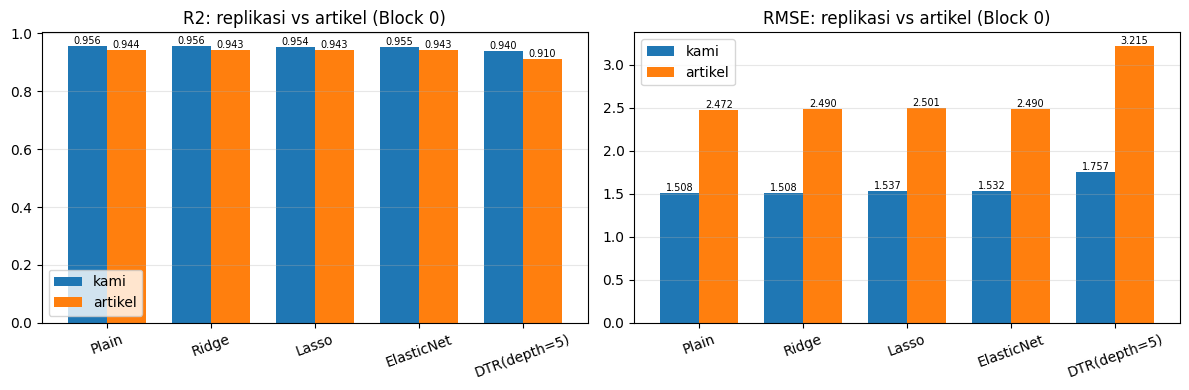

metrik,r2,mae,mse,rmse
model,,,,
Plain,1.28,-38.32,-62.80,-39.00
Ridge,1.39,-40.00,-63.34,-39.45
Lasso,1.21,-39.07,-62.24,-38.56
ElasticNet,1.24,-37.98,-62.17,-38.48
DTR(depth=5),3.33,-42.80,-70.12,-45.34


In [ ]:
SIMILAR_TOL = 0.01   # |selisih R²| di bawah ini disebut "hampir sama" (batas pribadi, bukan dari artikel)

# Tabel 6 artikel, kolom "For only one block (Block # 0)" (Ali et al., 2024, hlm. 19)
article_ref = pd.DataFrame([
    ("Plain",        0.944, 1.721,  6.112, 2.472, np.nan),
    ("Ridge",        0.943, 1.769,  6.202, 2.490, 0.001),
    ("Lasso",        0.943, 1.778,  6.253, 2.501, 0.001),
    ("ElasticNet",   0.943, 1.769,  6.202, 2.490, 0.001),
    ("DTR(depth=5)", 0.910, 2.004, 10.338, 3.215, np.nan),
], columns=["model", "r2", "mae", "mse", "rmse", "best_lam"])
article_ref.to_csv(RESULTS_DIR / "fase4_artikel_tabel6.csv", index=False)

metrics_order = ["r2", "mae", "mse", "rmse"]
metric_cmp = (res_df.melt(id_vars="model", value_vars=metrics_order, var_name="metrik", value_name="kami")
              .merge(article_ref.melt(id_vars="model", value_vars=metrics_order, var_name="metrik", value_name="artikel"),
                     on=["model", "metrik"])
              .assign(selisih=lambda x: x["kami"] - x["artikel"],
                      selisih_pct=lambda x: 100 * (x["kami"] - x["artikel"]) / x["artikel"]))
metric_cmp["model"] = pd.Categorical(metric_cmp["model"], categories=article_ref["model"], ordered=True)
metric_cmp["metrik"] = pd.Categorical(metric_cmp["metrik"], categories=metrics_order, ordered=True)
metric_cmp = metric_cmp.sort_values(["model", "metrik"]).reset_index(drop=True)
metric_cmp.round(4).to_csv(RESULTS_DIR / "fase4_perbandingan_metrik.csv", index=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for ax, k in zip((ax1, ax2), ["r2", "rmse"]):
    s = metric_cmp[metric_cmp["metrik"] == k].set_index("model")[["kami", "artikel"]]
    s.plot.bar(ax=ax, rot=20, width=.75)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.3f", fontsize=7)
    ax.set_xlabel(""); ax.set_title(f"{k.upper()}: replikasi vs artikel (Block 0)"); ax.grid(axis="y", alpha=.3)
save_fig("fase4_perbandingan_metrik")
metric_cmp.pivot(index="model", columns="metrik", values="selisih_pct").round(2)   # selisih relatif (%) kami vs artikel

### Sel 10 Cek klaim kualitatif artikel
Tiap baris adalah satu klaim artikel yang diperiksa terhadap `res_df` secara otomatis. Kolom `catatan` menjelaskan klaim yang wajar tidak cocok karena perbedaan setup.

In [ ]:
mpr_names = ["Plain", "Ridge", "Lasso", "ElasticNet"]
res_idx = res_df.set_index("model")
reg_names = ["Ridge", "Lasso", "ElasticNet"]

claim_check = pd.DataFrame([
    ("R² semua varian MPR lebih tinggi daripada DTR",
     "Tabel 6: MPR 0,943–0,944; DTR 0,91",
     f'MPR min {res_idx.loc[mpr_names, "r2"].min():.3f}; DTR {res_idx.at["DTR(depth=5)", "r2"]:.3f}',
     bool(res_idx.loc[mpr_names, "r2"].min() > res_idx.at["DTR(depth=5)", "r2"]), ""),
    ("RMSE DTR lebih besar daripada semua varian MPR",
     "Tabel 6: DTR 3,215; MPR 2,472–2,501",
     f'DTR {res_idx.at["DTR(depth=5)", "rmse"]:.3f}; MPR maks {res_idx.loc[mpr_names, "rmse"].max():.3f}',
     bool(res_idx.at["DTR(depth=5)", "rmse"] > res_idx.loc[mpr_names, "rmse"].max()), ""),
    ("Regularisasi vs Plain hampir sama (rentang R² empat varian MPR < SIMILAR_TOL)",
     "Teks hlm. 19: kinerja hampir sama; rentang R² 0,001",
     f'rentang R² {res_idx.loc[mpr_names, "r2"].max() - res_idx.loc[mpr_names, "r2"].min():.4f}',
     bool(res_idx.loc[mpr_names, "r2"].max() - res_idx.loc[mpr_names, "r2"].min() < SIMILAR_TOL), ""),
    ("Plain punya MAE terendah",
     "Tabel 6: Plain 1,721 (terendah)",
     f'MAE terendah: {res_idx["mae"].idxmin()} ({res_idx["mae"].min():.3f})',
     bool(res_idx["mae"].idxmin() == "Plain"), ""),
    ("ElasticNet ≈ Ridge (selisih R² < SIMILAR_TOL)",
     "Tabel 6: identik, karena α terpilih = 0",
     f'selisih R² {abs(res_idx.at["ElasticNet", "r2"] - res_idx.at["Ridge", "r2"]):.4f}',
     bool(abs(res_idx.at["ElasticNet", "r2"] - res_idx.at["Ridge", "r2"]) < SIMILAR_TOL),
     "Artikel menyetel α bersama λ; notebook ini mengunci α = 0,5, jadi hasil tidak harus identik dengan Ridge"),
    ("λ terpilih Ridge, Lasso, ElasticNet = 0,001",
     "Tabel 6: λ = 0,001 untuk ketiganya",
     ", ".join(f'{n}={res_idx.at[n, "best_lam"]:g}' for n in reg_names),
     bool(np.allclose(res_idx.loc[reg_names, "best_lam"].astype(float), 0.001)),
     "Grid λ artikel tidak dirinci; grid di sini = lam"),
    ("test_s varian regularisasi lebih kecil daripada Plain dan DTR",
     "Teks hlm. 21: waktu uji regularisasi paling rendah (tanpa angka; Gambar 17)",
     f'regularisasi maks {res_idx.loc[reg_names, "test_s"].max():.2f}s; Plain {res_idx.at["Plain", "test_s"]:.2f}s; DTR {res_idx.at["DTR(depth=5)", "test_s"]:.2f}s',
     bool(res_idx.loc[reg_names, "test_s"].max() < min(res_idx.at["Plain", "test_s"], res_idx.at["DTR(depth=5)", "test_s"])),
     "Waktu uji pada data kecil mode lokal sangat berisik (overhead Spark, warm-up); jalankan ulang beberapa kali"),
    ("fit_s Ridge lebih kecil daripada Lasso dan ElasticNet",
     "Teks hlm. 21: waktu fit Lasso dan ElasticNet lebih tinggi daripada Ridge",
     f'Ridge {res_idx.at["Ridge", "fit_s"]:.1f}s; Lasso {res_idx.at["Lasso", "fit_s"]:.1f}s; ElasticNet {res_idx.at["ElasticNet", "fit_s"]:.1f}s',
     bool(res_idx.at["Ridge", "fit_s"] < min(res_idx.at["Lasso", "fit_s"], res_idx.at["ElasticNet", "fit_s"])),
     "Bandingkan urutan, bukan nilai absolut (klaster Dataproc vs lokal)"),
    ("fit_s ElasticNet tertinggi di antara semua model",
     "Teks hlm. 21: ElasticNet paling lama karena grid λ × α",
     f'fit_s tertinggi: {res_idx["fit_s"].idxmax()} ({res_idx["fit_s"].max():.1f}s)',
     bool(res_idx["fit_s"].idxmax() == "ElasticNet"),
     "Di sini ElasticNet hanya menyetel λ (α tetap), jadi tidak diharapkan paling lama"),
], columns=["klaim", "artikel", "hasil_kami", "cocok", "catatan"])
claim_check.to_csv(RESULTS_DIR / "fase4_cek_klaim.csv", index=False)
print(f"Klaim cocok: {int(claim_check['cocok'].sum())} dari {len(claim_check)}")
claim_check

Klaim cocok: 4 dari 9


,klaim,artikel,hasil_kami,cocok,catatan
0,R² semua varian MPR lebih tinggi daripada DTR,"Tabel 6: MPR 0,943–0,944; DTR 0,91",MPR min 0.954; DTR 0.940,True,
1,RMSE DTR lebih besar daripada semua varian MPR,"Tabel 6: DTR 3,215; MPR 2,472–2,501",DTR 1.757; MPR maks 1.537,True,
2,Regularisasi vs Plain hampir sama (rentang R² ...,Teks hlm. 19: kinerja hampir sama; rentang R² ...,rentang R² 0.0017,True,
3,Plain punya MAE terendah,"Tabel 6: Plain 1,721 (terendah)",MAE terendah: Ridge (1.061),False,
4,ElasticNet ≈ Ridge (selisih R² < SIMILAR_TOL),"Tabel 6: identik, karena α terpilih = 0",selisih R² 0.0014,True,Artikel menyetel α bersama λ; notebook ini men...
5,"λ terpilih Ridge, Lasso, ElasticNet = 0,001","Tabel 6: λ = 0,001 untuk ketiganya","Ridge=0.0001, Lasso=0.0001, ElasticNet=0.001",False,Grid λ artikel tidak dirinci; grid di sini = lam
6,test_s varian regularisasi lebih kecil daripad...,Teks hlm. 21: waktu uji regularisasi paling re...,regularisasi maks 0.43s; Plain 0.57s; DTR 0.33s,False,Waktu uji pada data kecil mode lokal sangat be...
7,fit_s Ridge lebih kecil daripada Lasso dan Ela...,Teks hlm. 21: waktu fit Lasso dan ElasticNet l...,Ridge 29.0s; Lasso 24.1s; ElasticNet 21.8s,False,"Bandingkan urutan, bukan nilai absolut (klaste..."
8,fit_s ElasticNet tertinggi di antara semua model,Teks hlm. 21: ElasticNet paling lama karena gr...,fit_s tertinggi: Ridge (29.0s),False,"Di sini ElasticNet hanya menyetel λ (α tetap),..."


### Sel 11 Perbandingan korelasi (dasar seleksi fitur)

In [ ]:
# Korelasi: artikel melaporkan nilai absolut (Gambar 3 dan 4, hlm. 11-12)
article_corr = pd.DataFrame([
    ("energy_sum", "air_temp",  0.43, 0.43),
    ("energy_sum", "app_temp",  0.45, 0.45),
    ("energy_sum", "dew_point", 0.44, 0.44),
    ("air_temp",   "app_temp",  0.84, 0.99),   # artikel: rentang gabungan ketiga pasangan suhu = 0,84-0,99
    ("air_temp",   "dew_point", 0.84, 0.99),
    ("app_temp",   "dew_point", 0.84, 0.99),
], columns=["var_a", "var_b", "artikel_min", "artikel_max"])
assert {"air_temp", "app_temp", "dew_point"} <= set(corr_matrix.columns), "Kolom suhu tidak ada di corr_matrix (lihat wx_cols)"

corr_cmp = article_corr.assign(
    butir=article_corr["var_a"] + " ~ " + article_corr["var_b"],
    kami=[abs(corr_matrix.loc[a, b]) for a, b in zip(article_corr["var_a"], article_corr["var_b"])])
corr_cmp["selisih_ke_rentang"] = np.where(corr_cmp["kami"] < corr_cmp["artikel_min"], corr_cmp["kami"] - corr_cmp["artikel_min"],
                                 np.where(corr_cmp["kami"] > corr_cmp["artikel_max"], corr_cmp["kami"] - corr_cmp["artikel_max"], 0.0))
corr_cmp = corr_cmp[["butir", "artikel_min", "artikel_max", "kami", "selisih_ke_rentang"]]
corr_cmp.round(4).to_csv(RESULTS_DIR / "fase4_perbandingan_korelasi.csv", index=False)

# Alasan artikel memilih app_temp: korelasi tertinggi dengan energy_sum di antara kelompok suhu
top_temp = target_corr.loc[["air_temp", "app_temp", "dew_point"], "abs_r"].idxmax()
print(f"Suhu dengan |r| tertinggi terhadap energy_sum di datamu: {top_temp} (artikel: app_temp) -> {'sama' if top_temp == 'app_temp' else 'BERBEDA'}")
corr_cmp.round(3)

Suhu dengan |r| tertinggi terhadap energy_sum di datamu: app_temp (artikel: app_temp) -> sama


,butir,artikel_min,artikel_max,kami,selisih_ke_rentang
0,energy_sum ~ air_temp,0.43,0.43,0.232,-0.198
1,energy_sum ~ app_temp,0.45,0.45,0.241,-0.209
2,energy_sum ~ dew_point,0.44,0.44,0.213,-0.227
3,air_temp ~ app_temp,0.84,0.99,0.983,0.000
4,air_temp ~ dew_point,0.84,0.99,0.951,0.000
5,app_temp ~ dew_point,0.84,0.99,0.948,0.000


### Sel 12 Perbedaan setup replikasi vs artikel
Bahan utama Bagian D (keterbatasan dan perbedaan).

In [ ]:
setup_diff = pd.DataFrame([
    ("Data", "5.567 rumah, >167 juta rekaman; model per blok memakai Block 0 (±50 rumah)", "Block 0 saja (BLOCKS = [0])", "Sebanding dengan kolom Block 0 Tabel 6; kolom \"all houses\" tidak direplikasi"),
    ("Platform", "Google Dataproc: 1 master + 3 worker (2 vCPU, 7,5 GB), HDFS", "Spark mode lokal local[*]", "Waktu fit/uji tidak sebanding; hanya urutan antarmodel yang layak dibandingkan"),
    ("Sumber cuaca/libur", "Dark Sky API dan data bank holidays", "Salinan turunan Kaggle (Smart meters in London)", "Nilai suhu bisa sedikit berbeda"),
    ("Pembersihan", "Buang null dan nol; diagram alur juga mencantumkan eksklusi outlier", "Buang null, nol, dan negatif; tanpa eksklusi outlier", "Dampak kecil bila outlier sedikit"),
    ("Fitur", "count(LCLid), apparent temperature, hour, weekend (4 fitur)", "n_house, app_temp, hour, weekend", "Sama"),
    ("Praproses MPR", "One-hot encoding, polynomial expansion, standard scaling, eliminasi fitur kurang penting", "Polynomial expansion; standardisasi internal LinearRegression; tanpa one-hot dan tanpa eliminasi fitur", "Bisa mengubah akurasi MPR"),
    ("Derajat polinomial", "Tidak disebutkan di naskah", "POLY_DEGREE = 2 (asumsi)", "Tidak bisa diverifikasi; laporkan sebagai asumsi"),
    ("Split train/test", "Diagram menyebut data splitting, rasio tidak dirinci", "Acak 80/20, seed 42", "Tidak bisa diverifikasi; laporkan sebagai keterbatasan"),
    ("Cross-validation", "Dipakai untuk tuning; jumlah fold tidak dirinci; metrik tuning R²", "CV_FOLDS = 3; metrik tuning R²", "Jumlah fold asumsi"),
    ("Grid λ", "Tidak dirinci; λ terpilih 0,001 (Ridge, Lasso, ElasticNet)", "lam = [1e-5, 1e-4, 1e-3, 1e-2]", "Grid asumsi"),
    ("ElasticNet", "Menyetel λ dan α; α terpilih = 0 (setara Ridge)", "α tetap 0,5; hanya λ yang disetel", "ElasticNet tidak identik dengan Ridge dan waktu fit tidak mewakili grid λ × α"),
    ("DTR", "maxDepth = 5, tidak disetel", "maxDepth = 5, tidak disetel", "Sama"),
    ("Metrik dan waktu", "R², MAE, MSE, RMSE; waktu fit/uji tampil sebagai grafik (Gambar 17) tanpa angka", "r2, mae, mse, rmse, fit_s, test_s", "Bandingkan urutan waktu, bukan nilai"),
], columns=["aspek", "artikel", "replikasi", "dampak_ke_hasil"])
setup_diff.to_csv(RESULTS_DIR / "fase4_perbedaan_setup.csv", index=False)
setup_diff

,aspek,artikel,replikasi,dampak_ke_hasil
0,Data,"5.567 rumah, >167 juta rekaman; model per blok...",Block 0 saja (BLOCKS = [0]),Sebanding dengan kolom Block 0 Tabel 6; kolom ...
1,Platform,"Google Dataproc: 1 master + 3 worker (2 vCPU, ...",Spark mode lokal local[*],Waktu fit/uji tidak sebanding; hanya urutan an...
2,Sumber cuaca/libur,Dark Sky API dan data bank holidays,Salinan turunan Kaggle (Smart meters in London),Nilai suhu bisa sedikit berbeda
3,Pembersihan,Buang null dan nol; diagram alur juga mencantu...,"Buang null, nol, dan negatif; tanpa eksklusi o...",Dampak kecil bila outlier sedikit
4,Fitur,"count(LCLid), apparent temperature, hour, week...","n_house, app_temp, hour, weekend",Sama
5,Praproses MPR,"One-hot encoding, polynomial expansion, standa...",Polynomial expansion; standardisasi internal L...,Bisa mengubah akurasi MPR
6,Derajat polinomial,Tidak disebutkan di naskah,POLY_DEGREE = 2 (asumsi),Tidak bisa diverifikasi; laporkan sebagai asumsi
7,Split train/test,"Diagram menyebut data splitting, rasio tidak d...","Acak 80/20, seed 42",Tidak bisa diverifikasi; laporkan sebagai kete...
8,Cross-validation,Dipakai untuk tuning; jumlah fold tidak dirinc...,CV_FOLDS = 3; metrik tuning R²,Jumlah fold asumsi
9,Grid λ,"Tidak dirinci; λ terpilih 0,001 (Ridge, Lasso,...","lam = [1e-5, 1e-4, 1e-3, 1e-2]",Grid asumsi


In [ ]:
import shutil
import os

# 1. Zip folder 'figures'
if os.path.exists('figures'):
    shutil.make_archive('figures_download', 'zip', 'figures')
    print(" figures_download.zip berhasil dibuat.")

# 2. Zip folder 'results'
if os.path.exists('results'):
    shutil.make_archive('results_download', 'zip', 'results')
    print(" results_download.zip berhasil dibuat.")

# 3. Zip folder 'daily_dataset'
if os.path.exists('daily_dataset'):
    shutil.make_archive('daily_dataset_download', 'zip', 'daily_dataset')
    print("daily_dataset_download.zip berhasil dibuat.")

# 4. Zip folder 'data' (tanpa menyertakan file .zip besar di dalamnya)
if os.path.exists('data'):
    shutil.make_archive('data_download', 'zip', 'data')
    print("data_download.zip berhasil dibuat.")

 figures_download.zip berhasil dibuat.
 results_download.zip berhasil dibuat.
daily_dataset_download.zip berhasil dibuat.
data_download.zip berhasil dibuat.


In [ ]:
from google.colab import files
import os

# Daftar berkas zip yang siap diunduh
zip_files = [
    'figures_download.zip',
    'results_download.zip',
    'sample_data_download.zip',
    'daily_dataset_download.zip',
    'data_clean_download.zip'
]

for file_name in zip_files:
    if os.path.exists(file_name):
        print(f" Mengunduh {file_name}...")
        files.download(file_name)
    else:
        print(f" Berkas {file_name} tidak ditemukan.")

 Mengunduh figures_download.zip...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

 Mengunduh results_download.zip...


<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

 Mengunduh data_clean_download.zip...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>